# On the Theoretical Limitations of Embedding-Based Retrieval (Weller et al., ICLR 2026)

This notebook only reads the small JSON files that the scripts write to `outputs/` and compares them with the
paper's numbers. Nothing heavy is computed here.

## Getting the numbers

From the repository root, we can run everything using a single command (run it if `outputs` is missing):

```bash
python pairs/04-limit/run_scripts.py
```

## Setup

In [1]:
import json
import sys
from math import comb

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "scripts")
import limitlib

In [2]:
OUT = limitlib.OUT
SEEDS = [42, 1, 2]  # 42 is the seed of the official code; 1 and 2 show the run-to-run variation
SPLITS = ["limit-small", "limit"]
METRICS = {
    "limit-small": ["recall@2", "recall@10", "recall@20"],
    "limit": ["recall@2", "recall@10", "recall@100"],
}

pd.set_option("display.precision", 3)

BLUE = "#2a78d6"
ORANGE = "#eb6834"
AQUA = "#1baf7a"
RED = "#e34948"
GREY = "#b9b8b2"
INK = "#0b0b0b"
MUTED = "#52514e"

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 9,
    "axes.titlesize": 9.5,
    "axes.labelsize": 9,
    "legend.fontsize": 8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": MUTED,
    "axes.labelcolor": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "lines.linewidth": 1.6,
    "figure.dpi": 110,
})


def read(path, warn=True):
    """Loads a JSON file from outputs/, or returns None if it has not been produced yet."""
    path = OUT / path
    if not path.exists():
        if warn:
            print(f"missing: {path.relative_to(limitlib.HERE)}")
        return None
    return json.loads(path.read_text(encoding="utf-8"))


def seeded(setting, seed):
    """Output folder of a run: seed 42 has no suffix."""
    return setting if seed == 42 else f"{setting}_seed{seed}"

## The paper's numbers

Copied from the paper (Tables 4-6 and Figure 2).

In [3]:
# Table 6: critical n for k = 2
PAPER_CRITICAL_N = {
    4: 10, 5: 14, 6: 19, 7: 24, 8: 28, 9: 32, 10: 36, 11: 42, 12: 47, 13: 54,
    14: 62, 15: 70, 16: 79, 17: 89, 18: 99, 19: 109, 20: 120, 21: 132, 22: 144, 23: 157,
    24: 170, 25: 184, 26: 198, 27: 213, 28: 229, 29: 245, 30: 261, 31: 278, 32: 296, 33: 314,
    34: 333, 35: 352, 36: 372, 37: 392, 38: 413, 39: 434, 40: 460, 41: 484, 42: 505, 43: 545,
    44: 605, 45: 626,
}


# Figure 2: cubic fit of the critical n (r^2 = 0.999)
def paper_fit(d):
    return -10.5322 + 4.0309 * d + 0.0520 * d**2 + 0.0037 * d**3


# Tables 4 (LIMIT-small) and 5 (LIMIT): recall (%) of each single-vector model at each dimension
DIMS = [32, 64, 128, 256, 512, 768, 1024, 2048, 3072, 4096]

PAPER_LIMIT_SMALL = {
    "Qwen3-Embedding-8B": {
        "dims": DIMS,
        "recall@2": [8.3, 9.4, 11.6, 14.3, 16.1, 17.2, 17.8, 19.5, 19.3, 19.0],
        "recall@10": [30.6, 35.5, 38.3, 41.6, 43.7, 45.3, 48.7, 51.5, 52.8, 52.3],
        "recall@20": [53.9, 57.6, 60.8, 63.8, 66.0, 69.3, 70.3, 72.4, 73.3, 73.8],
    },
    "E5-Mistral 7B": {
        "dims": DIMS,
        "recall@2": [7.9, 10.2, 14.5, 15.3, 22.2, 21.6, 24.5, 28.9, 29.9, 29.5],
        "recall@10": [32.6, 37.0, 41.9, 45.9, 54.7, 57.5, 60.5, 66.3, 67.8, 68.1],
        "recall@20": [56.2, 60.3, 65.9, 69.7, 74.8, 79.2, 80.0, 83.2, 85.3, 85.2],
    },
    "GritLM 7B": {
        "dims": DIMS,
        "recall@2": [7.8, 9.4, 14.2, 17.3, 21.8, 23.8, 26.2, 33.0, 36.3, 38.4],
        "recall@10": [33.5, 35.9, 42.7, 46.2, 55.6, 58.1, 61.4, 69.1, 72.9, 75.4],
        "recall@20": [56.3, 59.6, 64.9, 68.3, 76.7, 80.1, 80.1, 86.2, 89.9, 90.5],
    },
    "Promptriever 8B": {
        "dims": DIMS,
        "recall@2": [6.1, 8.9, 13.7, 18.5, 27.0, 35.5, 38.0, 46.2, 49.2, 54.3],
        "recall@10": [31.4, 35.8, 44.5, 52.1, 61.8, 69.0, 73.5, 83.6, 87.3, 90.0],
        "recall@20": [56.0, 62.3, 67.6, 74.1, 81.7, 84.7, 89.1, 94.2, 96.6, 97.7],
    },
    "Gemini Embed": {
        "dims": [2, 4, 8, 16, 32, 64, 128, 256, 512, 768, 1024, 2048, 3072],
        "recall@2": [4.2, 4.2, 4.9, 5.2, 6.3, 6.9, 7.7, 14.6, 23.3, 28.8, 31.8, 31.9, 33.7],
        "recall@10": [23.0, 21.9, 23.2, 24.7, 25.2, 30.6, 37.0, 46.9, 58.4, 67.5, 69.9, 70.3, 72.4],
        "recall@20": [45.5, 46.0, 47.0, 47.5, 50.6, 55.0, 62.9, 69.7, 77.9, 84.5, 86.1, 87.1, 87.9],
    },
    "Snowflake Arctic L": {
        "dims": [32, 64, 128, 256, 512, 768, 1024],
        "recall@2": [8.3, 9.0, 12.7, 16.0, 16.7, 17.9, 19.4],
        "recall@10": [30.3, 35.4, 41.3, 48.2, 51.3, 53.5, 54.9],
        "recall@20": [53.8, 58.5, 65.1, 72.6, 74.1, 74.6, 76.0],
    },
}

PAPER_LIMIT_FULL = {
    "Qwen3-Embedding-8B": {
        "dims": DIMS,
        "recall@2": [0.0, 0.0, 0.3, 0.4, 0.6, 0.7, 0.7, 0.9, 0.8, 0.8],
        "recall@10": [0.1, 0.2, 0.4, 0.8, 1.3, 1.5, 1.6, 1.7, 1.6, 1.8],
        "recall@100": [1.1, 1.0, 1.8, 3.2, 3.3, 3.8, 4.6, 4.7, 4.8, 4.8],
    },
    "E5-Mistral 7B": {
        "dims": DIMS,
        "recall@2": [0.0, 0.0, 0.1, 0.4, 0.7, 0.9, 0.9, 1.0, 1.3, 1.3],
        "recall@10": [0.0, 0.1, 0.3, 0.9, 1.3, 1.7, 1.8, 1.9, 2.0, 2.2],
        "recall@100": [0.5, 0.4, 1.0, 1.9, 3.8, 4.3, 5.9, 6.8, 7.7, 8.3],
    },
    "GritLM 7B": {
        "dims": DIMS,
        "recall@2": [0.0, 0.0, 0.1, 0.1, 0.6, 1.5, 1.8, 2.3, 2.0, 2.4],
        "recall@10": [0.0, 0.1, 0.3, 0.4, 1.8, 3.1, 3.5, 4.3, 4.3, 4.1],
        "recall@100": [0.8, 0.3, 1.3, 2.8, 6.5, 8.7, 10.6, 11.8, 12.9, 12.9],
    },
    "Promptriever 8B": {
        "dims": DIMS,
        "recall@2": [0.0, 0.0, 0.0, 0.2, 0.6, 1.3, 2.1, 3.2, 2.9, 3.0],
        "recall@10": [0.0, 0.0, 0.1, 0.4, 1.4, 3.1, 4.4, 6.5, 6.3, 6.8],
        "recall@100": [0.1, 0.3, 0.6, 1.8, 5.4, 8.7, 12.8, 18.1, 17.8, 18.9],
    },
    "Gemini Embed": {
        "dims": [2, 4, 8, 16, 32, 64, 128, 256, 512, 768, 1024, 2048, 3072],
        "recall@2": [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.2, 0.9, 1.3, 1.5, 1.6],
        "recall@10": [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.1, 1.1, 2.5, 2.7, 3.1, 3.5],
        "recall@100": [0.1, 0.0, 0.0, 0.0, 0.0, 0.3, 0.3, 1.2, 3.6, 7.6, 8.1, 8.5, 10.0],
    },
    "Snowflake Arctic L": {
        "dims": [32, 64, 128, 256, 512, 768, 1024],
        "recall@2": [0.0, 0.2, 0.1, 0.2, 0.3, 0.4, 0.4],
        "recall@10": [0.1, 0.4, 0.3, 0.8, 1.0, 1.1, 0.8],
        "recall@100": [0.6, 1.7, 1.8, 2.5, 2.5, 3.1, 3.3],
    },
}

PAPER_TABLES = {"limit-small": PAPER_LIMIT_SMALL, "limit": PAPER_LIMIT_FULL}

PAPER_BM25 = {
    "limit-small": {"recall@2": 97.8, "recall@10": 100.0, "recall@20": 100.0},
    "limit": {"recall@2": 85.7, "recall@10": 90.4, "recall@100": 93.6},
}

PAPER_COLBERT = {
    "limit-small": {"recall@2": 83.5, "recall@10": 97.6, "recall@20": 99.1},
    "limit": {"recall@2": 23.1, "recall@10": 34.6, "recall@100": 54.8},
}

## 1. Free embedding in the paper's setting (Table 6)

One free unit vector per document and per query, one query for every pair of documents (k = 2), optimised directly
on the test qrels. The critical n is the largest number of documents for which every pair can still be returned as
an exact top 2. Our PyTorch port keeps the official hyper-parameters (see the docstring of
`scripts/free_embedding.py`).

In [4]:
rows = []
for d in [4, 8, 12, 16, 20, 24, 30, 45]:
    summary = read(f"free_embedding/synthetic_k2_d{d}/summary.json")
    if summary is None:
        continue
    row = {
        "d": d,
        "our critical n": summary["critical_n"],
        "paper (Table 6)": PAPER_CRITICAL_N[d],
        "paper's cubic fit": round(paper_fit(d), 1),
    }
    for seed in SEEDS[1:]:
        other = read(f"free_embedding/{seeded(f'synthetic_k2_d{d}', seed)}/summary.json", warn=False)
        row[f"seed {seed}"] = other["critical_n"] if other else None
    rows.append(row)

critical_n = pd.DataFrame(rows)
critical_n

,d,our critical n,paper (Table 6),paper's cubic fit,seed 1,seed 2
0,4,9,10,6.7,9.0,9.0
1,8,28,28,26.9,29.0,30.0
2,12,50,47,51.7,49.0,51.0
3,16,78,79,82.4,81.0,78.0
4,20,119,120,120.5,114.0,119.0
5,24,165,170,167.3,NaN,NaN
6,30,277,261,257.1,NaN,NaN
7,45,655,626,613.3,NaN,NaN


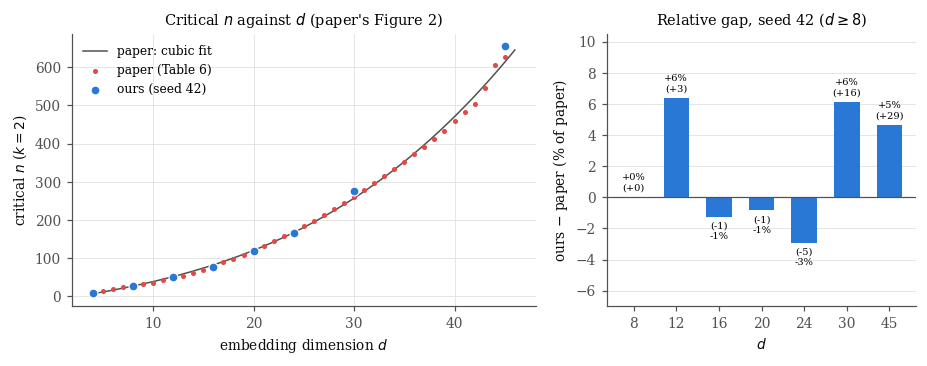

In [5]:
fig, (ax, ax_gap) = plt.subplots(1, 2, figsize=(8.5, 3.4), gridspec_kw={"width_ratios": [1.5, 1]})

# Left: critical n against d (the paper's Figure 2)
d_range = np.linspace(4, 46, 200)
ax.plot(d_range, paper_fit(d_range), color=MUTED, lw=1, label="paper: cubic fit")
ax.scatter(list(PAPER_CRITICAL_N), list(PAPER_CRITICAL_N.values()), s=11, color=RED, lw=0,
           label="paper (Table 6)", zorder=3)
ax.scatter(critical_n["d"], critical_n["our critical n"], s=34, color=BLUE, edgecolor="white", lw=0.8,
           label="ours (seed 42)", zorder=4)
ax.set_xlabel("embedding dimension $d$")
ax.set_ylabel("critical $n$ ($k=2$)")
ax.set_title("Critical $n$ against $d$ (paper's Figure 2)")
ax.legend(frameon=False, loc="upper left")

# Right: gap to the paper in %. d = 4 is left out: 9 against 10 is a single document, but shows as 10 %.
shown = critical_n[critical_n["d"] >= 8]
diff = shown["our critical n"] - shown["paper (Table 6)"]
gap = 100 * diff / shown["paper (Table 6)"]
ax_gap.bar(shown["d"].astype(str), gap, color=BLUE, width=0.6)
ax_gap.axhline(0, color=MUTED, lw=0.8)
for i, (pct, n) in enumerate(zip(gap, diff)):
    if pct >= 0:
        ax_gap.text(i, pct + 0.3, f"{pct:+.0f}%\n({n:+d})", ha="center", va="bottom", fontsize=6.5)
    else:
        ax_gap.text(i, pct - 0.3, f"({n:+d})\n{pct:+.0f}%", ha="center", va="top", fontsize=6.5)
ax_gap.set_xlabel("$d$")
ax_gap.set_ylabel("ours $-$ paper (% of paper)")
ax_gap.set_title(r"Relative gap, seed 42 ($d \geq 8$)")
ax_gap.set_ylim(-7, 10.5)
ax_gap.grid(axis="x", visible=False)

fig.tight_layout()
plt.show()

## 2. Free embedding on real qrels: the smallest d that fits them exactly

Same optimisation, but the qrels are a dataset's test labels over its whole corpus, with each query's own number of
relevant documents. If even free vectors need a large d, no encoder of that size can fit the labels.

The *co-relevance density* (the paper's Appendix F, our reading of it) is the share of query pairs that share a
relevant document. The paper reports 0.0014 for SciFact and 0.085 for LIMIT.

In [6]:
QRELS = ["scifact", "nfcorpus", "arguana", "limit-small", "limit"]


def co_relevance_density(name):
    _, _, qrels = limitlib.load_any(name)
    queries_of_doc = {}
    for query, relevant in qrels.items():
        for doc, grade in relevant.items():
            if grade > 0:
                queries_of_doc.setdefault(doc, set()).add(query)
    pairs = set()
    for queries in queries_of_doc.values():
        for a in queries:
            for b in queries:
                if a < b:
                    pairs.add((a, b))
    return len(pairs) / comb(len(qrels), 2)


rows = []
for name in QRELS:
    summary = read(f"free_embedding/{name}/summary.json")
    if summary is None:
        continue
    row = {
        "qrels": name,
        "queries": summary["n_queries"],
        "documents": summary["n_docs"],
        "relevant pairs": summary["n_relevant"],
        "relevant / query": round(summary["n_relevant"] / summary["n_queries"], 1),
        "co-relevance density": f"{co_relevance_density(name):.4g}",
        "smallest d (exact fit)": summary["min_d"],
    }
    for seed in SEEDS[1:]:
        other = read(f"free_embedding/{seeded(name, seed)}/summary.json", warn=False)
        row[f"seed {seed}"] = other["min_d"] if other else None
    rows.append(row)

pd.DataFrame(rows)

,qrels,queries,documents,relevant pairs,relevant / query,co-relevance density,smallest d (exact fit),seed 1,seed 2
0,scifact,300,5183,339,1.1,0.001449,5,5,6
1,nfcorpus,323,3633,12334,38.2,0.08196,29,24,27
2,arguana,1401,8674,1401,1.0,0,7,7,7
3,limit-small,1000,46,2000,2.0,0.08548,12,12,12
4,limit,1000,50000,2000,2.0,0.08548,15,16,15


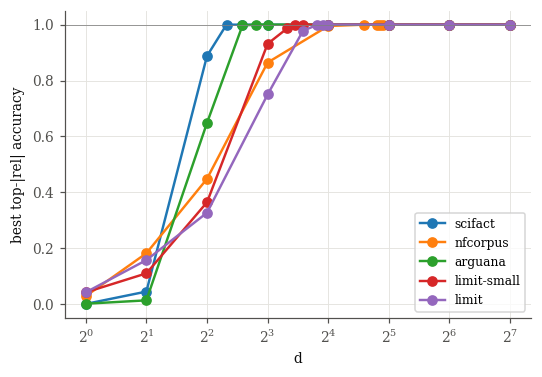

In [7]:
# Best accuracy reached at each d tried by the search (seed 42)
plt.figure(figsize=(5, 3.5))
for name in QRELS:
    summary = read(f"free_embedding/{name}/summary.json", warn=False)
    if summary is None:
        continue
    points = sorted((int(d), result["accuracy"]) for d, result in summary["tried"].items())
    dims, accuracy = zip(*points)
    plt.plot(dims, accuracy, marker="o", label=name)

plt.axhline(1, color="grey", lw=0.5)
plt.xscale("log", base=2)
plt.xlabel("d")
plt.ylabel("best top-|rel| accuracy")
plt.legend()
plt.tight_layout()
plt.show()

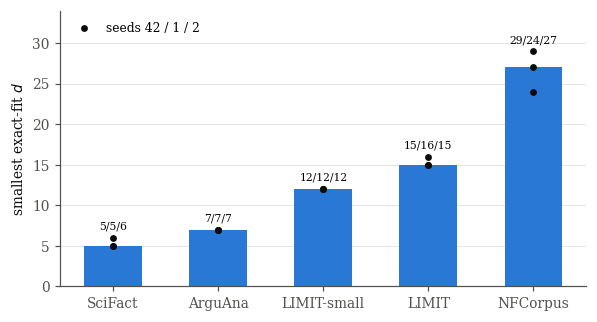

In [8]:
# Smallest exact-fit d for each seed; the bar is the median of the three
names = {"scifact": "SciFact", "arguana": "ArguAna", "limit-small": "LIMIT-small", "limit": "LIMIT",
         "nfcorpus": "NFCorpus"}

fig, ax = plt.subplots(figsize=(5.5, 3))
for i, name in enumerate(names):
    min_d = []
    for seed in SEEDS:
        summary = read(f"free_embedding/{seeded(name, seed)}/summary.json", warn=False)
        if summary:
            min_d.append(summary["min_d"])
    if not min_d:
        continue
    ax.bar(i, np.median(min_d), 0.55, color=BLUE)
    ax.scatter([i] * len(min_d), min_d, s=12, color=INK, zorder=3, label="seeds 42 / 1 / 2" if i == 0 else None)
    ax.text(i, max(min_d) + 0.8, "/".join(map(str, min_d)), ha="center", va="bottom", fontsize=7)

ax.set_xticks(range(len(names)), labels=names.values())
ax.set_ylabel("smallest exact-fit $d$")
ax.set_ylim(0, 34)
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
plt.show()

## 3. Real models on LIMIT (Tables 4 and 5)

Recall@k is the share of a query's two relevant documents in its top k. Qwen3-Embedding-8B, BM25 and
GTE-ModernColBERT are the paper's own systems; bge-small and Qwen3-Embedding-0.6B are the laptop-sized ones.
Section 4 explains the ColBERT gap.

In [9]:
def limit_results(split, system):
    """{run name: {"label", "recall@2", ...}}; one entry per dimension for the Qwen3 models."""
    result = read(f"limit/{split}/{system}.json")
    return result["systems"] if result else {}


def recall_by_dim(split, system, metric):
    results = limit_results(split, system)
    dims = [int(name.split("@")[1]) for name in results]
    return dims, [r[metric] for r in results.values()]


def limit_table(split):
    rows = []
    for system in ["bm25", "bge", "qwen3", "qwen3-8b", "colbert"]:
        for r in limit_results(split, system).values():
            rows.append({"system": r["label"], **{m: r[m] for m in METRICS[split]}})

    qwen8 = PAPER_TABLES[split]["Qwen3-Embedding-8B"]
    rows.append({"system": "paper: BM25", **PAPER_BM25[split]})
    rows.append({"system": "paper: GTE-ModernColBERT", **PAPER_COLBERT[split]})
    rows.append({"system": "paper: Qwen3-Embedding-8B (4096d)", **{m: qwen8[m][-1] for m in METRICS[split]}})
    return pd.DataFrame(rows)

In [10]:
for split in SPLITS:
    print(split)
    display(limit_table(split))

limit-small


,system,recall@2,recall@10,recall@20
0,BM25,97.90,100.00,100.00
1,bge-small-en-v1.5 (384d),9.55,37.90,62.40
2,Qwen3-Embedding-0.6B (32d),7.55,30.00,52.95
3,Qwen3-Embedding-0.6B (64d),9.80,32.20,55.95
4,Qwen3-Embedding-0.6B (128d),10.75,35.50,58.40
5,Qwen3-Embedding-0.6B (256d),12.90,38.15,59.45
6,Qwen3-Embedding-0.6B (512d),13.75,39.45,62.40
7,Qwen3-Embedding-0.6B (1024d),14.40,41.45,63.55
8,Qwen3-Embedding-8B (32d),8.10,30.35,54.45
9,Qwen3-Embedding-8B (64d),8.55,33.80,58.45


limit


,system,recall@2,recall@10,recall@100
0,BM25,85.75,90.30,93.65
1,bge-small-en-v1.5 (384d),0.05,0.35,1.85
2,Qwen3-Embedding-0.6B (32d),0.00,0.00,0.70
3,Qwen3-Embedding-0.6B (64d),0.05,0.20,1.70
4,Qwen3-Embedding-0.6B (128d),0.20,0.60,1.90
5,Qwen3-Embedding-0.6B (256d),0.75,1.15,2.35
6,Qwen3-Embedding-0.6B (512d),0.95,1.65,3.80
7,Qwen3-Embedding-0.6B (1024d),0.95,1.75,3.70
8,Qwen3-Embedding-8B (32d),0.00,0.10,0.90
9,Qwen3-Embedding-8B (64d),0.05,0.20,0.70


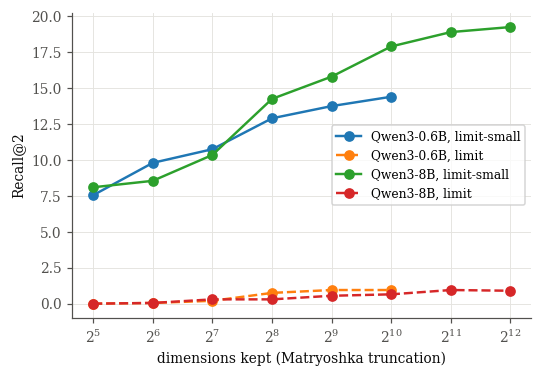

In [11]:
# Recall@2 as the Qwen3 embeddings are truncated (Matryoshka)
plt.figure(figsize=(5, 3.5))
for system, label in [("qwen3", "Qwen3-0.6B"), ("qwen3-8b", "Qwen3-8B")]:
    for split, style in [("limit-small", "-o"), ("limit", "--o")]:
        dims, recall = recall_by_dim(split, system, "recall@2")
        plt.plot(dims, recall, style, label=f"{label}, {split}")

plt.xscale("log", base=2)
plt.xlabel("dimensions kept (Matryoshka truncation)")
plt.ylabel("Recall@2")
plt.legend()
plt.tight_layout()
plt.show()

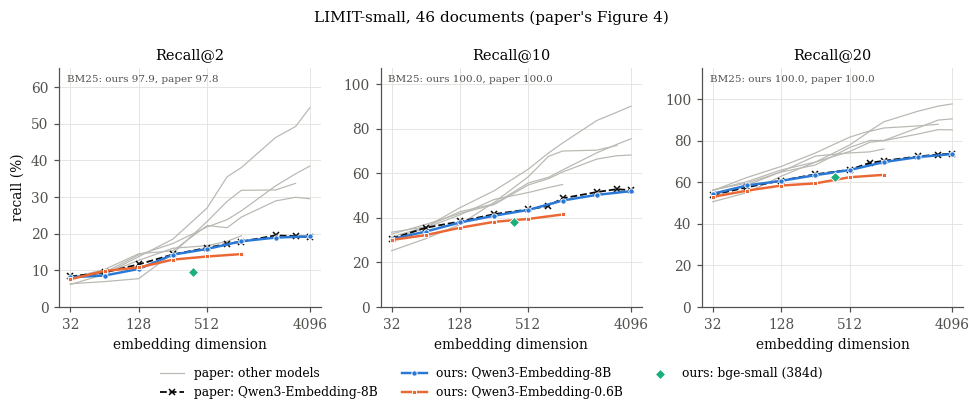

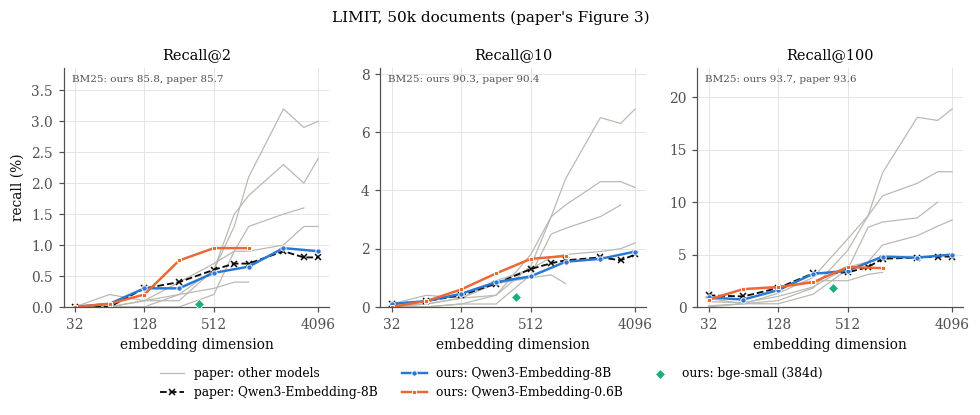

In [12]:
def plot_limit(split, title):
    """The paper's Figure 3 or 4 with our runs on top. Grey: the paper's other models."""
    paper = PAPER_TABLES[split]
    bm25 = next(iter(limit_results(split, "bm25").values()))
    bge = next(iter(limit_results(split, "bge").values()))

    fig, axes = plt.subplots(1, 3, figsize=(9, 3.3), sharex=True)
    for ax, metric in zip(axes, METRICS[split]):
        others = [model for model in paper if model != "Qwen3-Embedding-8B"]
        for i, model in enumerate(others):
            dims = np.array(paper[model]["dims"])
            keep = dims >= 32  # the axis starts at 32 dimensions
            ax.plot(dims[keep], np.array(paper[model][metric])[keep], color=GREY, lw=0.8,
                    label="paper: other models" if i == 0 else None)

        qwen8 = paper["Qwen3-Embedding-8B"]
        ax.plot(qwen8["dims"], qwen8[metric], color=INK, lw=1.2, ls="--", marker="x", ms=4,
                label="paper: Qwen3-Embedding-8B")
        ax.plot(*recall_by_dim(split, "qwen3-8b", metric), color=BLUE, marker="o", ms=3.5, mec="white", mew=0.6,
                label="ours: Qwen3-Embedding-8B")
        ax.plot(*recall_by_dim(split, "qwen3", metric), color=ORANGE, marker="s", ms=3, mec="white", mew=0.6,
                label="ours: Qwen3-Embedding-0.6B")
        ax.scatter([384], [bge[metric]], marker="D", s=22, color=AQUA, edgecolor="white", lw=0.6, zorder=4,
                   label="ours: bge-small (384d)")

        ax.set_title(metric.replace("recall", "Recall"))
        ax.set_xscale("log", base=2)
        ax.set_xticks([32, 128, 512, 4096], labels=["32", "128", "512", "4096"])
        ax.minorticks_off()
        ax.set_xlim(32 / 1.25, 4096 * 1.25)
        ax.set_ylim(0, ax.get_ylim()[1] * 1.15)  # room for the BM25 note
        ax.set_xlabel("embedding dimension")
        ax.text(0.03, 0.97, f"BM25: ours {bm25[metric]:.1f}, paper {PAPER_BM25[split][metric]:.1f}",
                transform=ax.transAxes, ha="left", va="top", fontsize=6.8, color=MUTED)

    axes[0].set_ylabel("recall (%)")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.12))
    fig.suptitle(title, fontsize=10)
    fig.tight_layout()
    plt.show()


plot_limit("limit-small", "LIMIT-small, 46 documents (paper's Figure 4)")
plot_limit("limit", "LIMIT, 50k documents (paper's Figure 3)")

## 4. Why our ColBERT beats the paper's: query expansion

Same checkpoint, five settings (`scripts/colbert_diagnosis.py`). When the paper was written (Aug 2025), the model's
configuration had query length 32 and no `do_query_expansion` key, so PyLate padded every query with [MASK] tokens
up to 32. The model's authors switched expansion off on 2025-09-09. MTEB is the paper's evaluation pipeline (a PLAID
index, not exact MaxSim).

In [13]:
VARIANTS = ["default", "qlen32", "paper-era", "mteb", "mteb-paper-era"]

for split in SPLITS:
    rows = []
    for variant in VARIANTS:
        r = read(f"limit/{split}/colbert_diagnosis/{variant}.json")
        if r is None:
            continue
        rows.append({
            "variant": variant,
            "pipeline": r["pipeline"],
            "query settings": str(r["settings"]),
            **{m: r[m] for m in ["recall@2", "recall@10", "recall@20", "recall@100"]},
        })
    rows.append({"variant": "paper (Table 4/5)", **PAPER_COLBERT[split]})
    print(split)
    display(pd.DataFrame(rows))

limit-small


,variant,pipeline,query settings,recall@2,recall@10,recall@20,recall@100
0,default,exact MaxSim (limitlib),model defaults,99.75,100.00,100.00,100.0
1,qlen32,exact MaxSim (limitlib),"{'query_length': 32, 'do_query_expansion': False}",99.75,100.00,100.00,100.0
2,paper-era,exact MaxSim (limitlib),"{'query_length': 32, 'do_query_expansion': True}",83.15,97.60,99.15,100.0
3,mteb,MTEB 2.27.7,model defaults,99.70,100.00,100.00,100.0
4,mteb-paper-era,MTEB 2.27.7,"{'query_length': 32, 'do_query_expansion': True}",80.80,97.15,98.65,100.0
5,paper (Table 4/5),NaN,NaN,83.50,97.60,99.10,NaN


limit


,variant,pipeline,query settings,recall@2,recall@10,recall@20,recall@100
0,default,exact MaxSim (limitlib),model defaults,95.1,97.85,98.20,99.05
1,qlen32,exact MaxSim (limitlib),"{'query_length': 32, 'do_query_expansion': False}",95.1,97.85,98.20,99.05
2,paper-era,exact MaxSim (limitlib),"{'query_length': 32, 'do_query_expansion': True}",22.9,34.45,40.75,55.35
3,mteb,MTEB 2.27.7,model defaults,81.0,87.10,88.20,89.70
4,mteb-paper-era,MTEB 2.27.7,"{'query_length': 32, 'do_query_expansion': True}",9.8,16.60,20.50,32.30
5,paper (Table 4/5),NaN,NaN,23.1,34.60,NaN,54.80


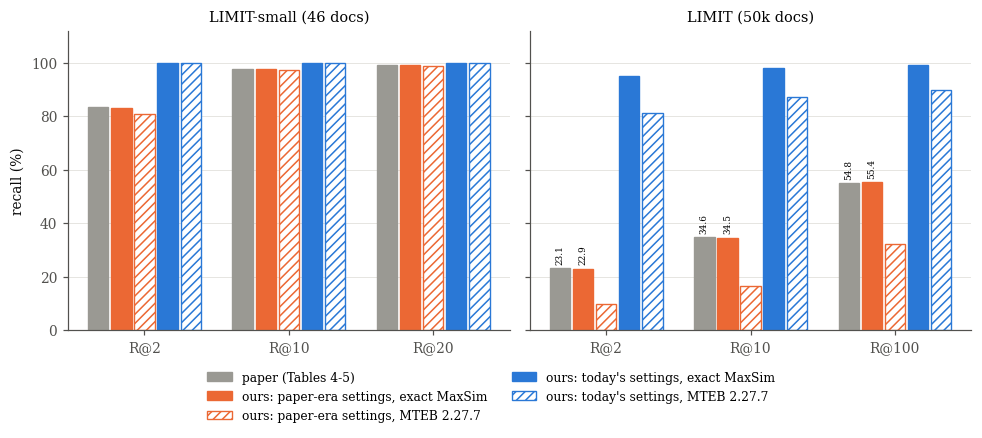

In [14]:
# Orange: the settings the model had when the paper was written. Blue: today's settings.
# Hatched: scored with MTEB 2.27.7 (the paper's pipeline) instead of exact MaxSim.
bars = [
    # (variant, label, colour, hatch)
    ("paper", "paper (Tables 4-5)", "#9a9993", None),
    ("paper-era", "ours: paper-era settings, exact MaxSim", ORANGE, None),
    ("mteb-paper-era", "ours: paper-era settings, MTEB 2.27.7", ORANGE, "////"),
    ("default", "ours: today's settings, exact MaxSim", BLUE, None),
    ("mteb", "ours: today's settings, MTEB 2.27.7", BLUE, "////"),
]
width = 0.16

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for ax, split in zip(axes, SPLITS):
    metrics = METRICS[split]
    x = np.arange(len(metrics))
    for i, (variant, label, colour, hatch) in enumerate(bars):
        if variant == "paper":
            result = PAPER_COLBERT[split]
        else:
            result = read(f"limit/{split}/colbert_diagnosis/{variant}.json")
        values = [result[m] for m in metrics]
        positions = x + (i - 2) * width
        ax.bar(positions, values, width * 0.88, color="white" if hatch else colour, edgecolor=colour,
               hatch=hatch, lw=0.9, label=label)
        if split == "limit" and variant in ("paper", "paper-era"):
            for pos, value in zip(positions, values):
                ax.text(pos, value + 1.5, f"{value:.1f}", ha="center", va="bottom", fontsize=5.8, rotation=90)
    ax.set_xticks(x, labels=[m.replace("recall", "R") for m in metrics])
    ax.set_title("LIMIT-small (46 docs)" if split == "limit-small" else "LIMIT (50k docs)")
    ax.set_ylim(0, 112)
    ax.grid(axis="x", visible=False)

axes[0].set_ylabel("recall (%)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.17))
fig.tight_layout()
plt.show()

## 5. The testbed row

`results.json` (GTE-ModernColBERT, multi-vector) and `results_qwen3.json` (Qwen3-Embedding-0.6B, single vector),
both against bge-small with the shared script. Two variants were tried, so read the p-values with that in mind.

In [15]:
rows = []
for file in ["results.json", "results_qwen3.json"]:
    path = limitlib.HERE / file
    if not path.exists():
        print(f"missing: {file}")
        continue
    result = json.loads(path.read_text(encoding="utf-8"))
    for dataset, scores in result["datasets"].items():
        vs_bge = scores["ndcg10_vs_baseline"]
        rows.append({
            "method": result["method"],
            "dataset": dataset,
            "nDCG@10": scores["ndcg10"],
            "bge": scores["baseline"]["ndcg10"],
            "delta": vs_bge["delta"],
            "95 % CI": vs_bge["ci95"],
            "p": vs_bge["p"],
            "Recall@100": scores["recall100"],
        })

pd.DataFrame(rows)

,method,dataset,nDCG@10,bge,delta,95 % CI,p,Recall@100
0,"LIMIT (GTE-ModernColBERT, MaxSim)",scifact,0.757,0.710,0.047,"[0.0176, 0.0764]",1.578e-03,0.963
1,"LIMIT (GTE-ModernColBERT, MaxSim)",nfcorpus,0.375,0.340,0.035,"[0.0167, 0.0532]",2.739e-04,0.322
2,"LIMIT (GTE-ModernColBERT, MaxSim)",arguana,0.431,0.606,-0.175,"[-0.1945, -0.155]",2.842e-61,0.935
3,LIMIT (Qwen3-Embedding-0.6B),scifact,0.689,0.710,-0.021,"[-0.0494, 0.0072]",1.328e-01,0.957
4,LIMIT (Qwen3-Embedding-0.6B),nfcorpus,0.362,0.340,0.022,"[0.0042, 0.0401]",1.693e-02,0.325
5,LIMIT (Qwen3-Embedding-0.6B),arguana,0.690,0.606,0.084,"[0.0685, 0.0989]",2.191e-26,0.996
